In [ ]:
import kagglehub
jp797498e_twitter_entity_sentiment_analysis_path = kagglehub.dataset_download('jp797498e/twitter-entity-sentiment-analysis')

print('Data source import complete.')


Using Colab cache for faster access to the 'twitter-entity-sentiment-analysis' dataset.
Data source import complete.


In [ ]:


import numpy as np
import pandas as pd

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

/kaggle/input/twitter-entity-sentiment-analysis/twitter_validation.csv
/kaggle/input/twitter-entity-sentiment-analysis/twitter_training.csv


In [ ]:
!pip install --upgrade --force-reinstall sympy==1.13.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 75.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 11.0 MB/s  0:00:00
  Attempting uninstall: mpmath
    Found existing installation: mpmath 1.3.0
    Uninstalling mpmath-1.3.0:
      Successfully uninstalled mpmath-1.3.0
  Attempting uninstall: sympy━━━━━━━━━━━━━━━━━━━ 0/2 [mpmath]
    Found existing installation: sympy 1.14.0 0/2 [mpmath]
    Uninstalling sympy-1.14.0:0m╺━━━━━━━━━━━━━━━━━━━ 1/2 [sympy]
      Successfully uninstalled sympy-1.14.0━━━━━━━━━━━━━━━━━━━ 1/2 [sympy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sympy]32m1/2 [sympy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu128 requires sympy>=1.13.3, but you have sympy 1.13.1 which is incompatible.


In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/jp797498e/twitter-entity-sentiment-analysis/twitter_training.csv
/kaggle/input/datasets/jp797498e/twitter-entity-sentiment-analysis/twitter_validation.csv


In [ ]:
import os

for file in os.listdir("/kaggle/working"):
    path = os.path.join("/kaggle/working", file)
    if os.path.isfile(path):
        print(file, round(os.path.getsize(path) / (1024**2), 2), "MB")

In [ ]:
import torch
import sympy
import transformers

print("PyTorch:", torch.__version__)
print("SymPy:", sympy.__version__)
print("Transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

from transformers import AutoTokenizer, AutoModelForSequenceClassification

print("All imports successful!")

PyTorch: 2.11.0+cu128
SymPy: 1.13.1
Transformers: 5.16.1
GPU: Tesla T4
All imports successful!


In [ ]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [ ]:
TRAIN_PATH = "/kaggle/input/datasets/jp797498e/twitter-entity-sentiment-analysis/twitter_training.csv"

VALID_PATH = "/kaggle/input/datasets/jp797498e/twitter-entity-sentiment-analysis/twitter_validation.csv"

In [ ]:
import pandas as pd

columns = ["id", "topic", "sentiment", "text"]

train_df = pd.read_csv(
    TRAIN_PATH,
    header=None,
    names=columns,
    encoding="utf-8"
)

valid_df = pd.read_csv(
    VALID_PATH,
    header=None,
    names=columns,
    encoding="utf-8"
)

print("Training shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

display(train_df.head())
display(valid_df.head())

Training shape: (74682, 4)
Validation shape: (1000, 4)


,id,topic,sentiment,text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


,id,topic,sentiment,text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...


In [ ]:
print("Training missing values:")
print(train_df.isnull().sum())

print("\nValidation missing values:")
print(valid_df.isnull().sum())

print("\nTraining duplicates:", train_df.duplicated().sum())
print("Validation duplicates:", valid_df.duplicated().sum())

print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())

Training missing values:
id             0
topic          0
sentiment      0
text         686
dtype: int64

Validation missing values:
id           0
topic        0
sentiment    0
text         0
dtype: int64

Training duplicates: 2700
Validation duplicates: 0

Sentiment distribution:
sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64


In [ ]:
# Remove rows with missing tweet text
train_df = train_df.dropna(subset=["text"]).copy()

# Remove duplicate rows
train_df = train_df.drop_duplicates().copy()

# Remove rows containing empty text
train_df["text"] = train_df["text"].astype(str).str.strip()
train_df = train_df[train_df["text"] != ""].copy()

# Reset index
train_df = train_df.reset_index(drop=True)

print("After cleaning:")
print("Training shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nDuplicates:", train_df.duplicated().sum())

After cleaning:
Training shape: (71484, 4)
Validation shape: (1000, 4)

Missing values:
id           0
topic        0
sentiment    0
text         0
dtype: int64

Duplicates: 367


In [ ]:
train_df = train_df.drop_duplicates(subset=["text"]).copy()

train_df = train_df.reset_index(drop=True)

print("Final training shape:", train_df.shape)
print("Duplicate tweets:", train_df["text"].duplicated().sum())

Final training shape: (69141, 4)
Duplicate tweets: 0


In [ ]:
import re

def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Keep letters, numbers, spaces, ! and ?
    text = re.sub(r"[^a-z0-9\s!?]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

train_df["clean_text"] = train_df["text"].apply(clean_text)
valid_df["clean_text"] = valid_df["text"].apply(clean_text)

print("Original tweet:")
print(train_df["text"].iloc[0])

print("\nCleaned tweet:")
print(train_df["clean_text"].iloc[0])

print("\nTraining shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

Original tweet:
im getting on borderlands and i will murder you all ,

Cleaned tweet:
im getting on borderlands and i will murder you all

Training shape: (69141, 5)
Validation shape: (1000, 5)


In [ ]:
label_map = {
    "Irrelevant": 0,
    "Negative": 1,
    "Neutral": 2,
    "Positive": 3
}

train_df["label"] = train_df["sentiment"].map(label_map)
valid_df["label"] = valid_df["sentiment"].map(label_map)

print("Label mapping:", label_map)

print("\nTraining label distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation label distribution:")
print(valid_df["label"].value_counts().sort_index())

print("\nSample:")
display(train_df[["sentiment", "clean_text", "label"]].head())

Label mapping: {'Irrelevant': 0, 'Negative': 1, 'Neutral': 2, 'Positive': 3}

Training label distribution:
label
0    12162
1    21088
2    16940
3    18951
Name: count, dtype: int64

Validation label distribution:
label
0    172
1    266
2    285
3    277
Name: count, dtype: int64

Sample:


,sentiment,clean_text,label
0,Positive,im getting on borderlands and i will murder yo...,3
1,Positive,i am coming to the borders and i will kill you...,3
2,Positive,im getting on borderlands and i will kill you all,3
3,Positive,im coming on borderlands and i will murder you...,3
4,Positive,im getting on borderlands 2 and i will murder ...,3


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    train_df["clean_text"],
    train_df["label"],
    test_size=0.10,
    random_state=42,
    stratify=train_df["label"]
)

print("Training samples:", len(X_train))
print("Internal validation samples:", len(X_val))

print("\nTraining distribution:")
print(y_train.value_counts().sort_index())

print("\nInternal validation distribution:")
print(y_val.value_counts().sort_index())

Training samples: 62226
Internal validation samples: 6915

Training distribution:
label
0    10945
1    18979
2    15246
3    17056
Name: count, dtype: int64

Internal validation distribution:
label
0    1217
1    2109
2    1694
3    1895
Name: count, dtype: int64


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "microsoft/deberta-v3-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Tokenizer loaded successfully!
Vocabulary size: 128000


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

# Configuration
BATCH_SIZE = 8
MAX_LENGTH = 96

class TwitterDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts.reset_index(drop=True)
        self.labels = labels.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        text = str(self.texts.iloc[index])
        label = int(self.labels.iloc[index])

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }


# Create datasets
train_dataset = TwitterDataset(
    X_train, y_train, tokenizer, MAX_LENGTH
)

val_dataset = TwitterDataset(
    X_val, y_val, tokenizer, MAX_LENGTH
)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Verify
batch = next(iter(train_loader))

print("Dataset preparation successful!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)
print("GPU available:", torch.cuda.is_available())

Dataset preparation successful!
Training samples: 62226
Validation samples: 6915
Input IDs shape: torch.Size([8, 96])
Attention mask shape: torch.Size([8, 96])
Labels shape: torch.Size([8])
GPU available: True


In [ ]:
import torch
from transformers import AutoModelForSequenceClassification

# Model configuration
NUM_LABELS = 4
MODEL_NAME = "microsoft/deberta-v3-base"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained DeBERTa model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label={
        0: "Irrelevant",
        1: "Negative",
        2: "Neutral",
        3: "Positive"
    },
    label2id={
        "Irrelevant": 0,
        "Negative": 1,
        "Neutral": 2,
        "Positive": 3
    }
)

model.to(device)

print("Model initialized successfully!")
print("Model:", MODEL_NAME)
print("Number of classes:", NUM_LABELS)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Total parameters:", sum(p.numel() for p in model.parameters()))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

model.safetensors: downloading bytes:           |  0.00B            

Model initialized successfully!
Model: microsoft/deberta-v3-base
Number of classes: 4
Device: cuda
GPU: Tesla T4
Total parameters: 184425220


In [ ]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Training configuration
EPOCHS = 4
LEARNING_RATE = 2e-5
GRADIENT_ACCUMULATION_STEPS = 2
WEIGHT_DECAY = 0.01

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Calculate total training steps
total_steps = (
    (len(train_loader) + GRADIENT_ACCUMULATION_STEPS - 1)
    // GRADIENT_ACCUMULATION_STEPS
) * EPOCHS

warmup_steps = int(0.1 * total_steps)

# Learning rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# Mixed precision
scaler = torch.amp.GradScaler("cuda")

print("Training configuration ready!")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print("Total optimizer steps:", total_steps)
print("Warmup steps:", warmup_steps)
print("Mixed precision: FP16")
print("Device:", device)

Training configuration ready!
Epochs: 4
Learning rate: 2e-05
Gradient accumulation: 2
Total optimizer steps: 15560
Warmup steps: 1556
Mixed precision: FP16
Device: cuda


In [ ]:
# Keep model parameters in FP32
model = model.float()

# Reinitialize optimizer
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Reset scheduler
from transformers import get_linear_schedule_with_warmup

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# Initialize GradScaler
scaler = torch.amp.GradScaler("cuda", enabled=True)

print("Model dtype:", next(model.parameters()).dtype)
print("GradScaler enabled:", scaler.is_enabled())
print("Device:", device)

Model dtype: torch.float32
GradScaler enabled: True
Device: cuda


In [ ]:
EPOCHS = 4
LEARNING_RATE = 2e-5
GRADIENT_ACCUMULATION_STEPS = 2
WEIGHT_DECAY = 0.01

print("EPOCHS =", EPOCHS)
print("Configuration loaded successfully!")

EPOCHS = 4
Configuration loaded successfully!


In [ ]:
import torch
from transformers import AutoModelForSequenceClassification

MODEL_NAME = "microsoft/deberta-v3-base"
NUM_LABELS = 4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label={
        0: "Irrelevant",
        1: "Negative",
        2: "Neutral",
        3: "Positive"
    },
    label2id={
        "Irrelevant": 0,
        "Negative": 1,
        "Neutral": 2,
        "Positive": 3
    }
)

model = model.float().to(device)

print("Model loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", device)
print("Data type:", next(model.parameters()).dtype)

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Model loaded successfully!
Model: microsoft/deberta-v3-base
Device: cuda
Data type: torch.float32


In [ ]:
import torch
import os
import gc
import pandas as pd

from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Training configuration
EPOCHS = 4
LEARNING_RATE = 2e-5
GRADIENT_ACCUMULATION_STEPS = 2
WEIGHT_DECAY = 0.01

# Check required objects
assert "model" in globals(), "Run the model initialization cell first."
assert "train_loader" in globals(), "Run the DataLoader cell first."
assert "val_loader" in globals(), "Run the DataLoader cell first."

# Ensure FP32 model parameters
model = model.float()

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Scheduler
total_steps = (
    (len(train_loader) + GRADIENT_ACCUMULATION_STEPS - 1)
    // GRADIENT_ACCUMULATION_STEPS
) * EPOCHS

warmup_steps = int(0.1 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# Mixed precision scaler
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

# Checkpoint locations
SAVE_DIR = "/kaggle/working/Twitter_Sentiment_Model"
BEST_DIR = "/kaggle/working/Twitter_Sentiment_Model_Best"

os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(BEST_DIR, exist_ok=True)

# Training history
history = []
best_f1 = 0.0

print("All training variables initialized!")
print("Optimizer:", type(optimizer).__name__)
print("Scheduler steps:", total_steps)
print("Model dtype:", next(model.parameters()).dtype)
print("Device:", next(model.parameters()).device)

All training variables initialized!
Optimizer: AdamW
Scheduler steps: 15560
Model dtype: torch.float32
Device: cuda:0


In [ ]:
import os
import gc
import torch
import pandas as pd
import numpy as np

from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from tqdm.auto import tqdm

# ==========================================
# CONFIGURATION
# ==========================================

SAVE_DIR = "/kaggle/working/Twitter_Sentiment_Model"
os.makedirs(SAVE_DIR, exist_ok=True)

best_f1 = 0.0
history = []

# ==========================================
# TRAINING AND VALIDATION FUNCTIONS
# ==========================================

def train_one_epoch():
    model.train()

    total_loss = 0
    optimizer.zero_grad(set_to_none=True)

    progress = tqdm(train_loader, desc="Training")
    total_batches = len(train_loader)

    for step, batch in enumerate(progress):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        accumulation_count = min(
            GRADIENT_ACCUMULATION_STEPS,
            total_batches - (step // GRADIENT_ACCUMULATION_STEPS)
                * GRADIENT_ACCUMULATION_STEPS
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss / accumulation_count

        scaler.scale(loss).backward()

        total_loss += outputs.loss.item()

        if (
            (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0
            or (step + 1) == total_batches
        ):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            scaler.step(optimizer)
            scaler.update()

            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

        progress.set_postfix(
            loss=f"{outputs.loss.item():.4f}"
        )

    return total_loss / total_batches


def evaluate():
    model.eval()

    total_loss = 0
    predictions = []
    actual_labels = []

    with torch.no_grad():
        for batch in tqdm(val_loader, desc="Validation"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_loss += outputs.loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            predictions.extend(preds.cpu().numpy())
            actual_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(actual_labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    return (
        total_loss / len(val_loader),
        accuracy,
        precision,
        recall,
        f1
    )


# ==========================================
# TRAINING LOOP
# ==========================================

for epoch in range(EPOCHS):

    print(f"\n{'='*50}")
    print(f" EPOCH {epoch + 1}/{EPOCHS}")
    print(f"{'='*50}")

    train_loss = train_one_epoch()

    val_loss, accuracy, precision, recall, f1 = evaluate()

    print(f"\nTraining Loss:   {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Accuracy:        {accuracy * 100:.2f}%")
    print(f"Precision:       {precision * 100:.2f}%")
    print(f"Recall:          {recall * 100:.2f}%")
    print(f"Weighted F1:     {f1 * 100:.2f}%")

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "weighted_f1": f1
    })

    # Save latest checkpoint after every epoch
    model.save_pretrained(SAVE_DIR, safe_serialization=True)
    tokenizer.save_pretrained(SAVE_DIR)

    torch.save({
        "epoch": epoch + 1,
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_f1": max(best_f1, f1)
    }, os.path.join(SAVE_DIR, "training_state.pt"))

    # Save best model separately
    if f1 > best_f1:
        best_f1 = f1
        best_dir = os.path.join(
            "/kaggle/working",
            "Twitter_Sentiment_Model_Best"
        )

        model.save_pretrained(best_dir, safe_serialization=True)
        tokenizer.save_pretrained(best_dir)

        print("Best model checkpoint updated!")

    # Save training history
    pd.DataFrame(history).to_csv(
        "/kaggle/working/training_history.csv",
        index=False
    )

    print("Checkpoint saved successfully!")

    gc.collect()
    torch.cuda.empty_cache()


# ==========================================
# FINAL RESULTS
# ==========================================

history_df = pd.DataFrame(history)

print("\nTRAINING COMPLETED")
display(history_df)

print("Best Weighted F1:", round(best_f1 * 100, 2), "%")
print("Model saved at:", SAVE_DIR)
print("Training history saved at: /kaggle/working/training_history.csv")


 EPOCH 1/4


Training:   0%|          | 0/7779 [00:00<?, ?it/s]

Validation:   0%|          | 0/865 [00:00<?, ?it/s]


Training Loss:   0.9392
Validation Loss: 0.6311
Accuracy:        76.60%
Precision:       77.06%
Recall:          76.60%
Weighted F1:     76.72%


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (17 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model checkpoint updated!
Checkpoint saved successfully!

TRAINING COMPLETED


,epoch,train_loss,val_loss,accuracy,precision,recall,weighted_f1
0,1,0.939173,0.631066,0.766016,0.770555,0.766016,0.767225
1,2,0.480386,0.414051,0.867824,0.871683,0.867824,0.866664
2,3,0.233835,0.383149,0.909617,0.910831,0.909617,0.909092
3,4,0.136289,0.357606,0.924078,0.924095,0.924078,0.923950


Best Weighted F1: 92.39 %
Model saved at: /kaggle/working/Twitter_Sentiment_Model
Training history saved at: /kaggle/working/training_history.csv


In [ ]:
import os
import pandas as pd

for folder in [
    "/kaggle/working/Twitter_Sentiment_Model",
    "/kaggle/working/Twitter_Sentiment_Model_Best"
]:
    print("\n", folder)
    for file in os.listdir(folder):
        path = os.path.join(folder, file)
        if os.path.isfile(path):
            print(file, round(os.path.getsize(path) / (1024**2), 2), "MB")

print("\nTraining history:")
display(pd.read_csv("/kaggle/working/training_history.csv"))


 /kaggle/working/Twitter_Sentiment_Model
model.safetensors 703.55 MB
tokenizer.json 7.95 MB
config.json 0.0 MB
training_state.pt 1407.22 MB
tokenizer_config.json 0.0 MB

 /kaggle/working/Twitter_Sentiment_Model_Best
model.safetensors 703.55 MB
tokenizer.json 7.95 MB
config.json 0.0 MB
tokenizer_config.json 0.0 MB

Training history:


,epoch,train_loss,val_loss,accuracy,precision,recall,weighted_f1
0,1,0.939173,0.631066,0.766016,0.770555,0.766016,0.767225
1,2,0.480386,0.414051,0.867824,0.871683,0.867824,0.866664
2,3,0.233835,0.383149,0.909617,0.910831,0.909617,0.909092
3,4,0.136289,0.357606,0.924078,0.924095,0.924078,0.923950


In [ ]:
import os

base = "/kaggle/working"

for folder in [
    "Twitter_Sentiment_Model",
    "Twitter_Sentiment_Model_Best"
]:
    path = os.path.join(base, folder)

    print(f"\n{folder}:",
          "EXISTS" if os.path.isdir(path) else "NOT FOUND")

    if os.path.isdir(path):
        for file in os.listdir(path):
            full_path = os.path.join(path, file)
            if os.path.isfile(full_path):
                print(file, round(os.path.getsize(full_path) / (1024**2), 2), "MB")


Twitter_Sentiment_Model: EXISTS
model.safetensors 703.55 MB
tokenizer.json 7.95 MB
config.json 0.0 MB
training_state.pt 1407.22 MB
tokenizer_config.json 0.0 MB

Twitter_Sentiment_Model_Best: EXISTS
model.safetensors 703.55 MB
tokenizer.json 7.95 MB
config.json 0.0 MB
tokenizer_config.json 0.0 MB


In [ ]:
import os
import zipfile

base = "/kaggle/working"
zip_path = os.path.join(base, "Twitter_Sentiment_Project.zip")

items = [
    "Twitter_Sentiment_Model_Best",
    "training_history.csv",
    "independent_evaluation_results.csv",
    "independent_predictions.csv",
    "plots"
]

# Remove any previous ZIP
if os.path.exists(zip_path):
    os.remove(zip_path)

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_STORED
) as z:
    for item in items:
        path = os.path.join(base, item)

        if not os.path.exists(path):
            print("SKIPPED:", item)
            continue

        if os.path.isfile(path):
            z.write(path, arcname=item)

        elif os.path.isdir(path):
            for root, dirs, files in os.walk(path):
                for file in files:
                    full_path = os.path.join(root, file)
                    arcname = os.path.relpath(full_path, base)
                    z.write(full_path, arcname=arcname)

print("\nZIP CREATED:", os.path.exists(zip_path))
print("ZIP SIZE:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")


ZIP CREATED: True
ZIP SIZE: 0.7 GB


In [ ]:
import torch
import pandas as pd
import numpy as np

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best checkpoint
BEST_DIR = "/kaggle/working/Twitter_Sentiment_Model_Best"

eval_tokenizer = AutoTokenizer.from_pretrained(BEST_DIR)

eval_model = AutoModelForSequenceClassification.from_pretrained(
    BEST_DIR
).to(device)

eval_model.eval()

# Prepare independent validation data
eval_texts = valid_df["clean_text"].reset_index(drop=True)
eval_labels = valid_df["label"].reset_index(drop=True)

class EvaluationDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = eval_tokenizer(
            str(self.texts.iloc[index]),
            truncation=True,
            padding="max_length",
            max_length=96,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                int(self.labels.iloc[index]),
                dtype=torch.long
            )
        }

eval_dataset = EvaluationDataset(eval_texts, eval_labels)

eval_loader = DataLoader(
    eval_dataset,
    batch_size=8,
    shuffle=False
)

# Generate predictions
all_predictions = []
all_labels = []

with torch.no_grad():
    for batch in eval_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            outputs = eval_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(batch["labels"].numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)
recall = recall_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)
weighted_f1 = f1_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)

print("INDEPENDENT VALIDATION RESULTS")
print("=" * 45)
print(f"Samples:   {len(all_labels)}")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"Weighted F1: {weighted_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=[
        "Irrelevant",
        "Negative",
        "Neutral",
        "Positive"
    ],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

INDEPENDENT VALIDATION RESULTS
Samples:   1000
Accuracy:  96.50%
Precision: 96.53%
Recall:    96.50%
Weighted F1: 96.50%

Classification Report:
              precision    recall  f1-score   support

  Irrelevant       0.96      0.94      0.95       172
    Negative       0.97      0.98      0.98       266
     Neutral       0.98      0.96      0.97       285
    Positive       0.94      0.97      0.96       277

    accuracy                           0.96      1000
   macro avg       0.97      0.96      0.96      1000
weighted avg       0.97      0.96      0.97      1000


Confusion Matrix:
[[162   2   3   5]
 [  0 260   1   5]
 [  2   4 273   6]
 [  4   1   2 270]]


In [ ]:
import pandas as pd
import os

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "Weighted F1"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        weighted_f1
    ]
})

results.to_csv(
    "/kaggle/working/independent_evaluation_results.csv",
    index=False
)

predictions_df = pd.DataFrame({
    "Actual": all_labels,
    "Predicted": all_predictions
})

predictions_df.to_csv(
    "/kaggle/working/independent_predictions.csv",
    index=False
)

print("Evaluation results saved!")
print("Independent accuracy:", round(accuracy * 100, 2), "%")
print("Files saved in /kaggle/working/")

Evaluation results saved!
Independent accuracy: 96.5 %
Files saved in /kaggle/working/


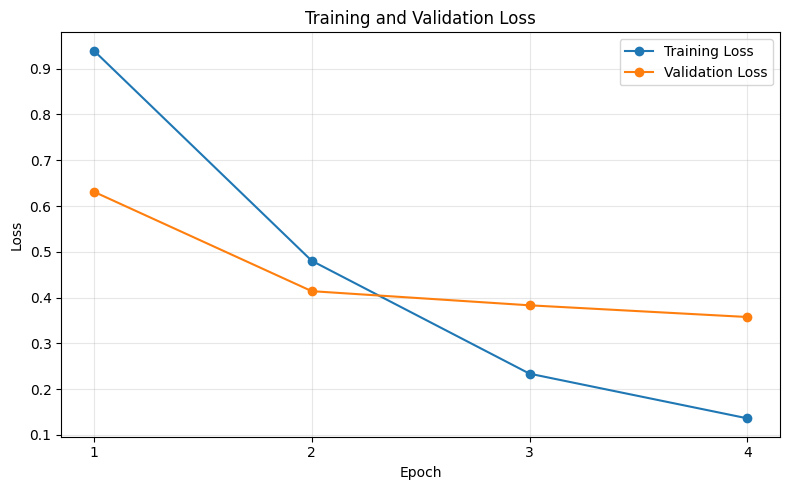

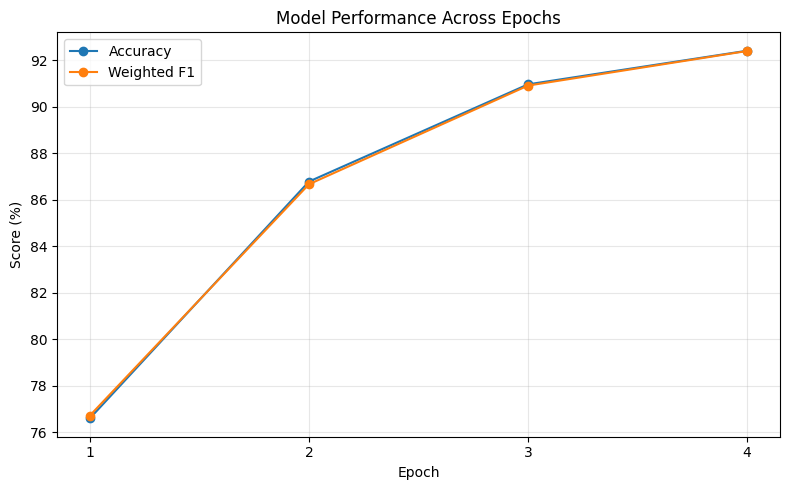

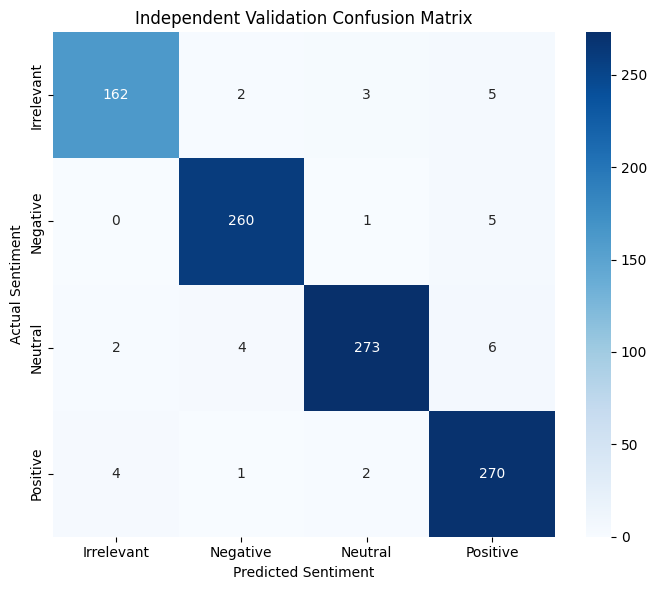

All three plots saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os

# Load training history
history_df = pd.read_csv(
    "/kaggle/working/training_history.csv"
)

os.makedirs("/kaggle/working/plots", exist_ok=True)

# 1. Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"],
         marker="o", label="Training Loss")
plt.plot(history_df["epoch"], history_df["val_loss"],
         marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/plots/loss_curve.png", dpi=300)
plt.show()

# 2. Accuracy and Weighted F1
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["accuracy"] * 100,
         marker="o", label="Accuracy")
plt.plot(history_df["epoch"], history_df["weighted_f1"] * 100,
         marker="o", label="Weighted F1")
plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("Model Performance Across Epochs")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/plots/performance_curve.png", dpi=300)
plt.show()

# 3. Independent validation confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

labels = ["Irrelevant", "Negative", "Neutral", "Positive"]

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Independent Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "/kaggle/working/plots/confusion_matrix.png",
    dpi=300
)
plt.show()

print("All three plots saved successfully!")

In [ ]:
import os

zip_path = "/kaggle/working/Twitter_Sentiment_Analysis.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

In [ ]:
from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/Twitter_Sentiment_Analysis.zip"
))

In [ ]:
from IPython.display import display, HTML

display(HTML("""
<a href="files/Twitter_Sentiment_Analysis.zip" download>
    Download Twitter Sentiment Analysis ZIP
</a>
"""))

In [ ]:
import os
import zipfile

base = "/kaggle/working"
zip_path = os.path.join(base, "Twitter_Sentiment_Analysis.zip")

items = [
    "Twitter_Sentiment_Model",
    "Twitter_Sentiment_Model_Best",
    "training_history.csv",
    "independent_evaluation_results.csv",
    "independent_predictions.csv",
    "plots"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for item in items:
        path = os.path.join(base, item)

        if os.path.isfile(path):
            z.write(path, arcname=item)

        elif os.path.isdir(path):
            for root, dirs, files in os.walk(path):
                for file in files:
                    full_path = os.path.join(root, file)
                    arcname = os.path.relpath(full_path, base)
                    z.write(full_path, arcname)

print("ZIP ready:", os.path.exists(zip_path))
print("Size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

In [ ]:
import os

zip_path = "/kaggle/working/Twitter_Sentiment_Analysis.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

In [ ]:
import os
import zipfile

base = "/kaggle/working"
zip_path = os.path.join(base, "Twitter_Sentiment_Analysis.zip")

items = [
    "Twitter_Sentiment_Model",
    "Twitter_Sentiment_Model_Best",
    "training_history.csv",
    "independent_evaluation_results.csv",
    "independent_predictions.csv",
    "plots"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for item in items:
        path = os.path.join(base, item)

        if os.path.isfile(path):
            z.write(path, arcname=item)

        elif os.path.isdir(path):
            for root, dirs, files in os.walk(path):
                for file in files:
                    full_path = os.path.join(root, file)
                    arcname = os.path.relpath(full_path, base)
                    z.write(full_path, arcname)

print("ZIP created:", os.path.exists(zip_path))
print("ZIP size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

In [ ]:
import os

base = "/kaggle/working"

for item in [
    "Twitter_Sentiment_Model",
    "Twitter_Sentiment_Model_Best",
    "training_history.csv",
    "independent_evaluation_results.csv",
    "independent_predictions.csv",
    "plots"
]:
    path = os.path.join(base, item)

    if os.path.isfile(path):
        print(item, round(os.path.getsize(path) / (1024**2), 2), "MB")

    elif os.path.isdir(path):
        total = sum(
            os.path.getsize(os.path.join(root, f))
            for root, _, files in os.walk(path)
            for f in files
        )
        print(item, round(total / (1024**2), 2), "MB")

    else:
        print(item, "NOT FOUND")

In [ ]:
import os
import zipfile

base = "/kaggle/working"
zip_path = os.path.join(base, "Twitter_Sentiment_Project.zip")

items = [
    "Twitter_Sentiment_Model_Best/config.json",
    "Twitter_Sentiment_Model_Best/tokenizer.json",
    "Twitter_Sentiment_Model_Best/tokenizer_config.json",
    "training_history.csv",
    "independent_evaluation_results.csv",
    "independent_predictions.csv",
    "plots"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for item in items:
        path = os.path.join(base, item)

        if os.path.isfile(path):
            z.write(path, arcname=item)

        elif os.path.isdir(path):
            for root, dirs, files in os.walk(path):
                for file in files:
                    full_path = os.path.join(root, file)
                    arcname = os.path.relpath(full_path, base)
                    z.write(full_path, arcname=arcname)

print("ZIP created:", os.path.exists(zip_path))
print("Size:", round(os.path.getsize(zip_path) / (1024**2), 2), "MB")

In [ ]:
import os

base = "/kaggle/working"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for file in files:
        path = os.path.join(root, file)
        print(" ", file, round(os.path.getsize(path) / (1024**2), 2), "MB")


In [ ]:
import os

base = "/kaggle/working"

for name in os.listdir(base):
    path = os.path.join(base, name)
    if os.path.isdir(path):
        print("\nFOLDER:", name)
        for root, dirs, files in os.walk(path):
            for file in files:
                full_path = os.path.join(root, file)
                print(file, round(os.path.getsize(full_path) / (1024**2), 2), "MB")